# Longer ECG sections and temporal agreement

KEY-02, 6 November 2026. This is a prospective successor to `ConditionKeys.ipynb`.
The question is whether longer sections recover information lost by the previous 0.5–2-second
reference selection. The four overlapping groups remain MI, STTC, CD and HYP ECG annotations.
They are proxies, not verified diagnoses. All numerical findings below come from executed outputs.

## What ECG-JEPA contributes to the idea

[ECG-JEPA, sections 3.1–3.3](https://arxiv.org/html/2410.08559v2) uses synchronized temporal
masking across leads and Cross-Pattern Attention: patches connect along the same lead and across
leads at the same time. This structural bias is motivated by ECG interpretation. The paper does
not establish that the model reasons like a cardiologist.

Our cached xECG tokens already combine leads. This study tests longer temporal context and
agreement across sections. It does not implement CroPA, masked latent prediction, or a JEPA
encoder comparison. The median-score control is our experimental heuristic, not a method from
that paper. A direct lead-aware experiment requires lead-indexed representations.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path.cwd()
if not (ROOT / 'ecg_experiment').exists():
    ROOT = ROOT.parent
result = json.loads((ROOT / 'reports/long-section-keys-2026-11-06/aggregate.json').read_text())
private = np.load(ROOT / 'outputs/long_section_keys_20261106/artifacts.npz', allow_pickle=False)
assert result['status'] == 'completed'
groups = ['MI', 'STTC', 'CD', 'HYP']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Source commit:', result['git_commit'])
print('Reference ECGs:', result['counts']['training'])
print('SPH evaluation ECGs:', result['counts']['query'])
print('SPH patients:', result['counts']['query_patients'])
print('Integrity:', result['integrity'])


Source commit: 0acb4693e717f39f1f7dd4592ad4f2e9cc976752
Reference ECGs: 25000
SPH evaluation ECGs: 10434
SPH patients: 10116
Integrity: {'exact_metric_dictionaries': 10, 'primary_interval_exact': True, 'result_sha256': '8d8f5b92f065c2614f1fbf9c375232cb2cec2dda65344c0efc63ad72b47f5285', 'private_sha256': '0135113cbc65e1b1e73064c94422f74537c91aadd90a6473567726f183478619', 'whole_score_max_error': 0.0}


## Frozen design and data roles

The same 25,000 human-read-source reference ECGs and 10,434 SPH evaluation ECGs are used.
SPH never fits the scaler or keys. It is reused development data, not an untouched test.
The prior experiment's scores, metric dictionaries and primary patient interval reproduce exactly.
No closed Challenge/EchoNext test, new annotation, raw waveform or GPU is used.

Every 250 ms xECG token contains encoder context, so a span is not an independently encoded
waveform crop. Longer sections comprise 10, 20 or 30 tokens (2.5, 5 or 7.5 seconds).
All stride-one candidates are included: respectively 31, 21 and 11 windows per ECG.

Each arm starts from the same whole-record keys, chooses the highest-margin reference region
for positives and the lowest-margin region for normals, and averages these unit vectors once.
A query is scored by its maximum positive-minus-normal cosine margin. Two five-second controls
keep the whole-record keys and use either the maximum or the median window margin.
The median asks whether recurring evidence helps. Scores are not probabilities.

Five-second selected keys are the primary candidate. Advancement requires a macro-AUROC gain
of at least 0.01 over short selected keys, a positive lower 95% bound, and a point no more than
0.01 below whole-record keys. The final criterion is a descriptive guard, not noninferiority.
Other lengths cannot replace the primary candidate after seeing the results.


,macro AUROC,macro AP
arm,,
whole,0.896102,0.417818
short_selected,0.774030,0.259330
selected_2.5s,0.856926,0.344356
selected_5s,0.879836,0.384924
whole_keys_5s_max,0.895460,0.419443
whole_keys_5s_median,0.894789,0.417331
selected_7.5s,0.889927,0.406271


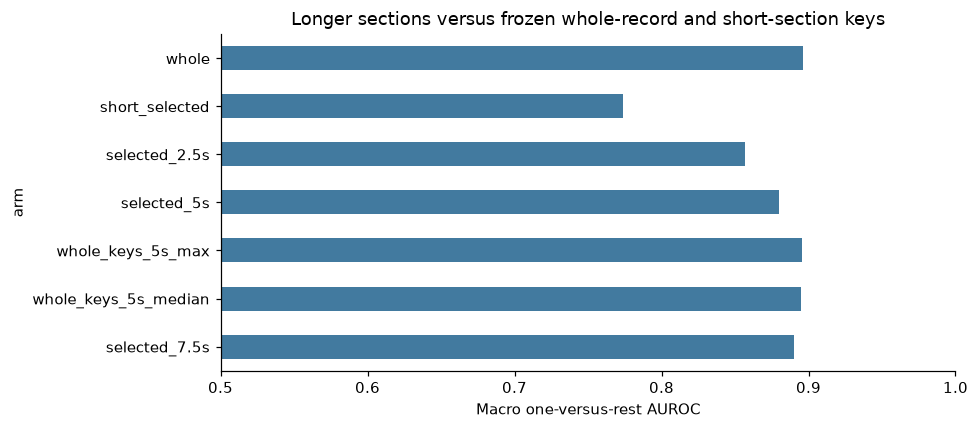

In [2]:
summary = pd.DataFrame({name: {
    'macro AUROC': value['macro_auroc'],
    'macro AP': value['macro_average_precision']}
    for name, value in result['metrics'].items()}).T
summary.index.name = 'arm'
display(summary.style.format('{:.6f}'))
summary['macro AUROC'].iloc[::-1].plot.barh(figsize=(9, 4), color='#427a9f')
plt.xlim(0.5, 1)
plt.xlabel('Macro one-versus-rest AUROC')
plt.title('Longer sections versus frozen whole-record and short-section keys')
plt.tight_layout()
plt.show()


## Primary contrast and practical guard

AUROC is computed separately for each group against all other evaluated ECGs, including other
abnormalities, then averaged across the four groups. The paired bootstrap resamples whole
patients 2,000 times with seed 20261103 and the same patients for both arms. Intervals condition
on one fixed reference cohort and encoder. The whole-record contrast is descriptive.


In [3]:
display(pd.DataFrame({
    '5s minus short selected': result['primary'],
    '5s minus whole record': result['versus_whole'],
}).T)
print('Decision:', result['decision'])
print('All advancement criteria passed:', result['decision']['advance'])


,difference,ci_low,ci_high,draws,skipped_draws,seed
5s minus short selected,0.105805,0.096213,0.115893,2000.0,0.0,20261103.0
5s minus whole record,-0.016266,-0.019793,-0.013137,2000.0,0.0,20261103.0


Decision: {'gain_at_least_0.01': True, 'lower_95_above_zero': True, 'within_0.01_of_whole_point': False, 'advance': False}
All advancement criteria passed: False


## Differences across annotation groups

A high average can hide poor recognition of a particular group. These per-group results are
descriptive; no separate confirmatory claims are made. Labels overlap, so this is not a forced
choice among four diseases. AP is prevalence-dependent, particularly for the rarer MI/HYP groups.


,whole,short_selected,selected_2.5s,selected_5s,whole_keys_5s_max,whole_keys_5s_median,selected_7.5s
MI,0.9245,0.7516,0.8776,0.9053,0.9236,0.9240,0.9169
STTC,0.9234,0.8278,0.8808,0.9058,0.9229,0.9226,0.9168
CD,0.8409,0.7362,0.8229,0.8401,0.8415,0.8393,0.8428
HYP,0.8956,0.7806,0.8465,0.8681,0.8938,0.8933,0.8831


,whole,short_selected,selected_2.5s,selected_5s,whole_keys_5s_max,whole_keys_5s_median,selected_7.5s
MI,0.2149,0.0471,0.1152,0.1582,0.2152,0.2190,0.1893
STTC,0.7956,0.6298,0.7170,0.7610,0.7957,0.7937,0.7820
CD,0.4561,0.2860,0.4257,0.4573,0.4519,0.4524,0.4617
HYP,0.2047,0.0743,0.1196,0.1633,0.2150,0.2042,0.1921


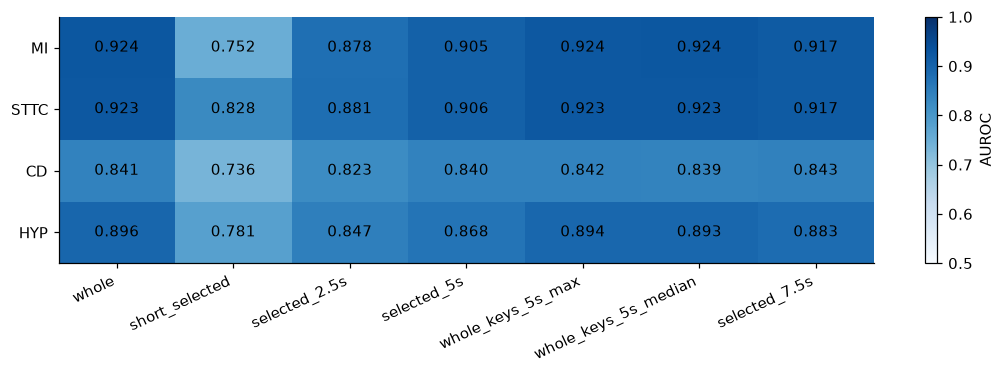

In [4]:
auroc = pd.DataFrame({arm: {g: v['groups'][g]['auroc'] for g in groups}
                      for arm, v in result['metrics'].items()})
ap = pd.DataFrame({arm: {g: v['groups'][g]['average_precision'] for g in groups}
                   for arm, v in result['metrics'].items()})
display(auroc.style.format('{:.4f}'))
display(ap.style.format('{:.4f}'))
fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(auroc.to_numpy(), vmin=0.5, vmax=1, cmap='Blues', aspect='auto')
ax.set(yticks=range(4), yticklabels=groups,
       xticks=range(len(auroc.columns)), xticklabels=auroc.columns)
plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
for row in range(4):
    for col in range(len(auroc.columns)):
        ax.text(col, row, f'{auroc.iloc[row, col]:.3f}', ha='center', va='center')
fig.colorbar(im, ax=ax, label='AUROC')
plt.tight_layout()
plt.show()


## Does repeated evidence help?

The maximum and median five-second controls share identical whole-record keys and candidate
windows. Their comparison isolates this query aggregation choice. It does not isolate CroPA,
lead agreement or clinician reasoning. Stronger performance with longer windows can reflect
retaining more context, fewer candidate windows, or reduced reference-selection extremes; this
experiment does not separate those mechanisms.


In [5]:
display(summary.loc[['whole', 'whole_keys_5s_max', 'whole_keys_5s_median']])
print('Median minus maximum macro AUROC:',
      summary.loc['whole_keys_5s_median', 'macro AUROC'] - summary.loc['whole_keys_5s_max', 'macro AUROC'])
normal = pd.Series({k: v['macro_auroc'] for k, v in result['condition_vs_normal'].items()})
display(pd.DataFrame({'against all others': summary['macro AUROC'], 'against normals only': normal}))


,macro AUROC,macro AP
arm,,
whole,0.896102,0.417818
whole_keys_5s_max,0.895460,0.419443
whole_keys_5s_median,0.894789,0.417331


Median minus maximum macro AUROC: -0.0006711673200965329


,against all others,against normals only
whole,0.896102,0.944959
short_selected,0.774030,0.825079
selected_2.5s,0.856926,0.908386
selected_5s,0.879836,0.929829
whole_keys_5s_max,0.895460,0.944242
whole_keys_5s_median,0.894789,0.943813
selected_7.5s,0.889927,0.939042


## Saved-output verification and interpretation

The following cells independently recompute all per-group AUROCs and average precisions from
saved scores. No model is refitted or selected. The prior notebook's clustering results remain
unchanged; this experiment does not refit or relabel those clusters.


In [6]:
checks = 0
flags = private['flags']
for arm in result['metrics']:
    scores = private['score_' + arm]
    for c, group in enumerate(groups):
        for normal_only, key in [(False, 'metrics'), (True, 'condition_vs_normal')]:
            keep = ((flags[:, c] == 1) | ~flags.any(axis=1)
                    if normal_only else np.ones(len(flags), dtype=bool))
            expected = result[key][arm]['groups'][group]
            assert roc_auc_score(flags[keep, c], scores[keep, c]) == expected['auroc']
            assert average_precision_score(flags[keep, c], scores[keep, c]) == expected['average_precision']
            checks += 2
print('Exact metric checks passed:', checks)
primary = result['primary']
print(f'Five seconds minus short sections: {primary["difference"]:+.6f}')
print(f'95% interval: [{primary["ci_low"]:+.6f}, {primary["ci_high"]:+.6f}]')
print('Advance longer-section keys:', result['decision']['advance'])
print('Actual JEPA/CroPA executed:', result['jepa_or_cropa_executed'])


Exact metric checks passed: 112
Five seconds minus short sections: +0.105805
95% interval: [+0.096213, +0.115893]
Advance longer-section keys: False
Actual JEPA/CroPA executed: False


## Scope and reproduction

Results concern existing ECG annotation groups on reused hospital development data. No unseen
disease identification, physiological delineation, clinical reasoning or student screening
performance is established. Project recommendations belong in the accompanying results report.

Run the scientific study in a fresh output location with
`python -m scripts.experiments.run_long_section_keys`; it requires original hash-bound local
caches and refuses overwrite. Rebuild this notebook with
`python -m scripts.reports.build_long_section_notebook` in the project environment.

OpenAI Codex assisted with the prospective design, implementation and explanation. All reported
numbers were executed locally; patient-level arrays remain local. The authors are responsible for
reviewing the scientific and clinical interpretation.
